### Chargement et Exploration Initiale des Données

In [1]:
import pandas as pd
import numpy as np

# Chemin du fichier
file_path = '/content/drive/MyDrive/DataSet_Credit.xlsx'

# Chargement du fichier Excel
df = pd.read_excel(file_path)

# Affichage des dimensions et des premières lignes
print(f"Dimensions du dataset : {df.shape}")
display(df.head())


Dimensions du dataset : (15189, 12)


,NUMERO_CREDIT,AGENCE,SECTEUR ACTIVITE,TYPE DE CREDIT,NUMERO_MEMBRE,ANNEE OUVERTURE,MOIS OUVERTURE,Age,Nombre de Crédit antérieur,SOLDE_CREDIT,MONTANT_DEBOURSE,RETARD
0,22847,MECYD,CONSOMMATION,CREDITS AFSSEF A LT DE + 3 ANS A 10 ANS AU +,2521,2023,4,52,6.0,303237.93,700000,0 JOUR
1,22849,MECYD,CONSTRUCTION,CREDITS AFSSEF A LT DE + 3 ANS A 10 ANS AU +,175,2023,4,52,6.0,563155.88,1300000,0 JOUR
2,22896,MECYD,CONSTRUCTION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,3776,2023,5,52,6.0,995330.03,2000000,0 JOUR
3,22941,MECYD,CONSOMMATION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,9049,2023,5,52,6.0,205577.41,450000,0 JOUR
4,22942,MECYD,CONSTRUCTION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,4275,2023,5,52,6.0,123473.53,500000,0 JOUR


In [2]:
# Analyse des types de données et des valeurs manquantes
print(df.info())

# Description statistique des variables numériques
display(df.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15189 entries, 0 to 15188
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   NUMERO_CREDIT               15189 non-null  int64  
 1   AGENCE                      15189 non-null  object 
 2   SECTEUR ACTIVITE            15189 non-null  object 
 3   TYPE DE CREDIT              15189 non-null  object 
 4   NUMERO_MEMBRE               15189 non-null  int64  
 5   ANNEE OUVERTURE             15189 non-null  int64  
 6   MOIS OUVERTURE              15189 non-null  int64  
 7   Age                         15189 non-null  int64  
 8   Nombre de Crédit antérieur  13179 non-null  float64
 9   SOLDE_CREDIT                15189 non-null  float64
 10  MONTANT_DEBOURSE            15189 non-null  int64  
 11  RETARD                      15188 non-null  object 
dtypes: float64(2), int64(6), object(4)
memory usage: 1.4+ MB
None


,NUMERO_CREDIT,AGENCE,SECTEUR ACTIVITE,TYPE DE CREDIT,NUMERO_MEMBRE,ANNEE OUVERTURE,MOIS OUVERTURE,Age,Nombre de Crédit antérieur,SOLDE_CREDIT,MONTANT_DEBOURSE,RETARD
count,15189.000000,15189,15189,15189,1.518900e+04,15189.000000,15189.000000,15189.000000,13179.000000,1.518900e+04,1.518900e+04,15188
unique,NaN,5,16,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
top,NaN,CEC_B,COMMERCE,CRÉDITS TRESORERIE FEMME AFSSEF CT DE + DE 6 ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0 JOUR
freq,NaN,5388,11417,6913,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12685
mean,83801.764764,NaN,NaN,NaN,2.137708e+07,2025.185990,5.639739,45.060109,3.708324,7.696178e+05,1.089963e+06,NaN
std,82928.044257,NaN,NaN,NaN,5.021151e+07,1.682917,3.259502,8.512567,1.290450,3.094233e+06,4.607067e+06,NaN
min,15708.000000,NaN,NaN,NaN,1.000000e+00,2017.000000,1.000000,2.000000,1.000000,1.000000e-02,5.000000e+04,NaN
25%,30964.000000,NaN,NaN,NaN,1.195500e+04,2025.000000,3.000000,45.000000,2.000000,1.383795e+05,2.000000e+05,NaN
50%,42892.000000,NaN,NaN,NaN,1.755700e+04,2026.000000,5.000000,50.000000,4.000000,2.500000e+05,4.000000e+05,NaN
75%,46825.000000,NaN,NaN,NaN,2.159900e+04,2026.000000,8.000000,50.000000,5.000000,5.456452e+05,9.000000e+05,NaN


### Étape 1 : Nettoyage et Préparation des Données

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

# 1. Copie du dataset
df_clean = df.copy()

# 2. Traitement des valeurs manquantes
# Remplacer les valeurs manquantes de 'Nombre de Crédit antérieur' par la médiane
median_credits = df_clean['Nombre de Crédit antérieur'].median()
df_clean['Nombre de Crédit antérieur'] = df_clean['Nombre de Crédit antérieur'].fillna(median_credits)

# Supprimer la ligne contenant un RETARD manquant
df_clean = df_clean.dropna(subset=['RETARD'])

# 3. Création de la variable cible binaire : 0 si '0 JOUR', 1 sinon
df_clean['CIBLE_RETARD'] = df_clean['RETARD'].apply(lambda x: 0 if str(x).strip() == '0 JOUR' else 1)

# 4. Suppression des variables inutiles pour la prédiction
features_to_drop = ['NUMERO_CREDIT', 'NUMERO_MEMBRE', 'RETARD']
df_clean = df_clean.drop(columns=features_to_drop)

# 5. Encodage des variables catégorielles
cat_cols = ['AGENCE', 'SECTEUR ACTIVITE', 'TYPE DE CREDIT']
for col in cat_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))

print("Distribution de la variable cible 'CIBLE_RETARD' :")
print(df_clean['CIBLE_RETARD'].value_counts(normalize=True))


Distribution de la variable cible 'CIBLE_RETARD' :
CIBLE_RETARD
0    0.835199
1    0.164801
Name: proportion, dtype: float64


### Étape 2 : Division, Entraînement et Évaluation des Modèles


=== Régression Logistique ===
Accuracy : 0.8443
AUC-ROC  : 0.8123

Rapport de classification :
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      2537
           1       0.55      0.32      0.40       501

    accuracy                           0.84      3038
   macro avg       0.71      0.63      0.66      3038
weighted avg       0.82      0.84      0.83      3038



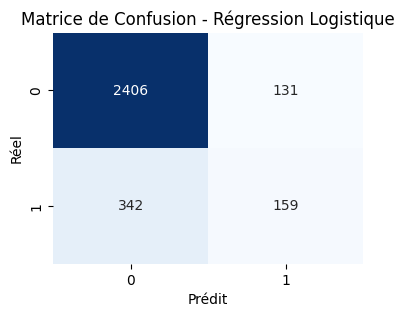


=== Random Forest ===
Accuracy : 0.9569
AUC-ROC  : 0.9618

Rapport de classification :
              precision    recall  f1-score   support

           0       0.96      0.99      0.97      2537
           1       0.93      0.79      0.86       501

    accuracy                           0.96      3038
   macro avg       0.95      0.89      0.92      3038
weighted avg       0.96      0.96      0.96      3038



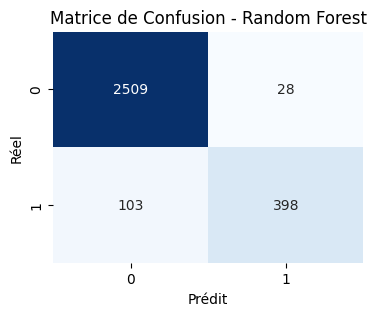


=== XGBoost ===


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:54:39] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Accuracy : 0.9608
AUC-ROC  : 0.9595

Rapport de classification :
              precision    recall  f1-score   support

           0       0.96      0.99      0.98      2537
           1       0.95      0.80      0.87       501

    accuracy                           0.96      3038
   macro avg       0.96      0.90      0.92      3038
weighted avg       0.96      0.96      0.96      3038



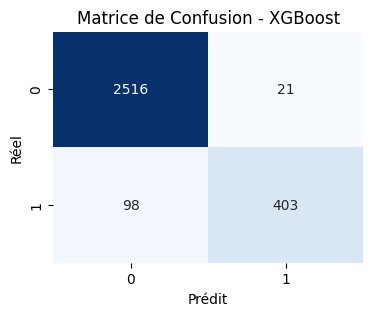

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Séparation des features (X) et de la cible (y)
X = df_clean.drop(columns=['CIBLE_RETARD'])
y = df_clean['CIBLE_RETARD']

# Division Train/Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Modèle principal : XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss',
    use_label_encoder=False
)

# Conserver les autres modèles uniquement en commentaire pour comparaison si besoin
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.linear_model import LogisticRegression
# models = {
#     "Régression Logistique": LogisticRegression(max_iter=1000, random_state=42),
#     "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
#     "XGBoost": xgb_model
# }

print("\n=== Modèle principal : XGBoost ===")
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)
y_proba = xgb_model.predict_proba(X_test)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC-ROC  : {roc_auc_score(y_test, y_proba):.4f}")
print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Matrice de Confusion - XGBoost")
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.show()

models = {"XGBoost": xgb_model}


### Étape 1 : Nettoyage et Préparation des Données

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

# 1. Copie du dataset
df_clean = df.copy()

# 2. Traitement des valeurs manquantes
# Remplacer les valeurs manquantes de 'Nombre de Crédit antérieur' par la médiane
median_credits = df_clean['Nombre de Crédit antérieur'].median()
df_clean['Nombre de Crédit antérieur'] = df_clean['Nombre de Crédit antérieur'].fillna(median_credits)

# Supprimer la ligne contenant un RETARD manquant
df_clean = df_clean.dropna(subset=['RETARD'])

# 3. Création de la variable cible binaire : 0 si '0 JOUR', 1 sinon
df_clean['CIBLE_RETARD'] = df_clean['RETARD'].apply(lambda x: 0 if str(x).strip() == '0 JOUR' else 1)

# 4. Suppression des variables inutiles pour la prédiction
features_to_drop = ['NUMERO_CREDIT', 'NUMERO_MEMBRE', 'RETARD']
df_clean = df_clean.drop(columns=features_to_drop)

# 5. Encodage des variables catégorielles
cat_cols = ['AGENCE', 'SECTEUR ACTIVITE', 'TYPE DE CREDIT']
for col in cat_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))

print("Distribution de la variable cible 'CIBLE_RETARD' :")
print(df_clean['CIBLE_RETARD'].value_counts(normalize=True))


Distribution de la variable cible 'CIBLE_RETARD' :
CIBLE_RETARD
0    0.835199
1    0.164801
Name: proportion, dtype: float64


### Étape 2 : Division, Entraînement et Évaluation des Modèles


=== Régression Logistique ===
Accuracy : 0.8443
AUC-ROC  : 0.8123

Rapport de classification :
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      2537
           1       0.55      0.32      0.40       501

    accuracy                           0.84      3038
   macro avg       0.71      0.63      0.66      3038
weighted avg       0.82      0.84      0.83      3038



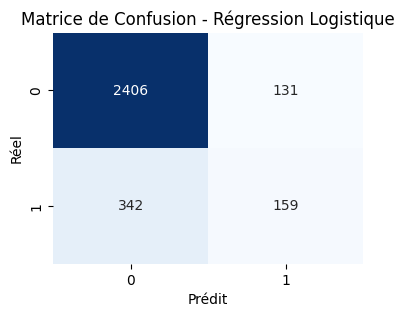


=== Random Forest ===
Accuracy : 0.9569
AUC-ROC  : 0.9618

Rapport de classification :
              precision    recall  f1-score   support

           0       0.96      0.99      0.97      2537
           1       0.93      0.79      0.86       501

    accuracy                           0.96      3038
   macro avg       0.95      0.89      0.92      3038
weighted avg       0.96      0.96      0.96      3038



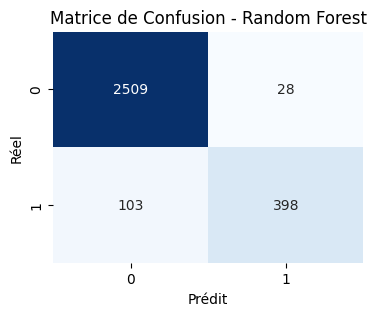


=== XGBoost ===
Accuracy : 0.9608
AUC-ROC  : 0.9595

Rapport de classification :
              precision    recall  f1-score   support

           0       0.96      0.99      0.98      2537
           1       0.95      0.80      0.87       501

    accuracy                           0.96      3038
   macro avg       0.96      0.90      0.92      3038
weighted avg       0.96      0.96      0.96      3038



/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:54:44] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


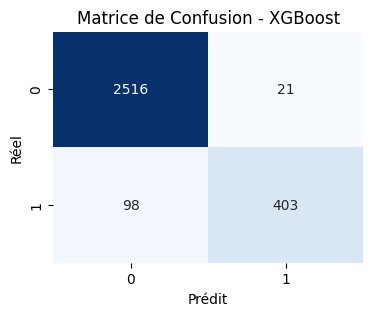

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Séparation des features (X) et de la cible (y)
X = df_clean.drop(columns=['CIBLE_RETARD'])
y = df_clean['CIBLE_RETARD']

# Division Train/Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Modèle principal : XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss',
    use_label_encoder=False
)

# Conserver les autres modèles uniquement en commentaire pour comparaison si besoin
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.linear_model import LogisticRegression
# models = {
#     "Régression Logistique": LogisticRegression(max_iter=1000, random_state=42),
#     "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
#     "XGBoost": xgb_model
# }

print("\n=== Modèle principal : XGBoost ===")
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)
y_proba = xgb_model.predict_proba(X_test)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC-ROC  : {roc_auc_score(y_test, y_proba):.4f}")
print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Matrice de Confusion - XGBoost")
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.show()

models = {"XGBoost": xgb_model}


### Étape 3 : Courbe ROC Comparative

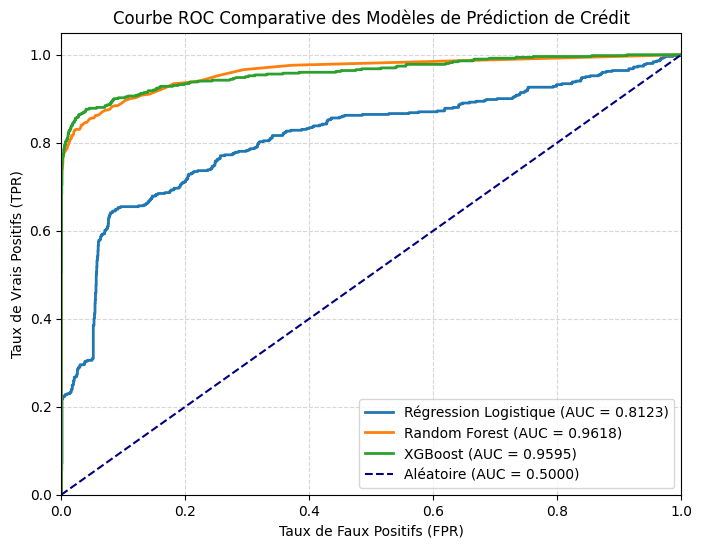

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Courbe ROC du modèle principal XGBoost
model = models['XGBoost']
y_proba = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc:.4f})', lw=2)

# Ligne de référence aléatoire
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Aléatoire (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs (FPR)')
plt.ylabel('Taux de Vrais Positifs (TPR)')
plt.title('Courbe ROC du Modèle XGBoost')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### Étape 4 : Analyse de l'Importance des Variables avec XGBoost

/tmp/ipykernel_1357/3367051518.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Variable', data=feature_importance_df, palette='viridis')


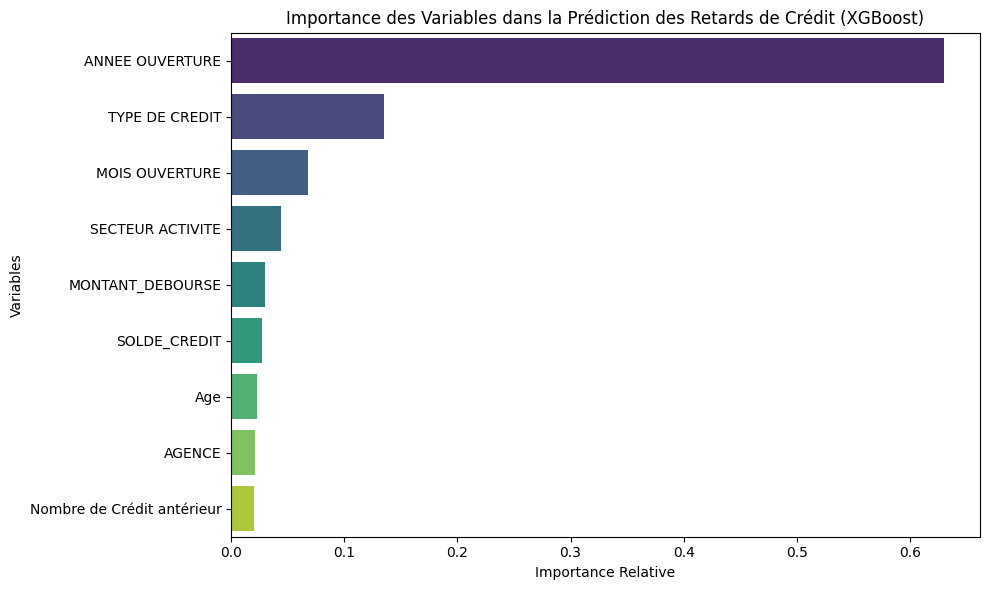

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Récupération du modèle XGBoost entraîné
xgb_model = models["XGBoost"]

# Calcul de l'importance des variables
importances = xgb_model.feature_importances_
feature_names = X.columns

# Création d'un DataFrame trié pour l'affichage
feature_importance_df = pd.DataFrame({
    'Variable': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Visualisation graphique
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Variable', data=feature_importance_df, palette='viridis')
plt.title('Importance des Variables dans la Prédiction des Retards de Crédit (XGBoost)')
plt.xlabel('Importance Relative')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

### Étape 5 : Analyse des Corrélations avec la Cible

Coefficients de corrélation avec CIBLE_RETARD :
TYPE DE CREDIT                0.368816
AGENCE                        0.029636
MONTANT_DEBOURSE              0.020035
SOLDE_CREDIT                  0.003408
MOIS OUVERTURE               -0.050723
Nombre de Crédit antérieur   -0.074142
SECTEUR ACTIVITE             -0.074230
Age                          -0.208742
ANNEE OUVERTURE              -0.650405
Name: CIBLE_RETARD, dtype: float64


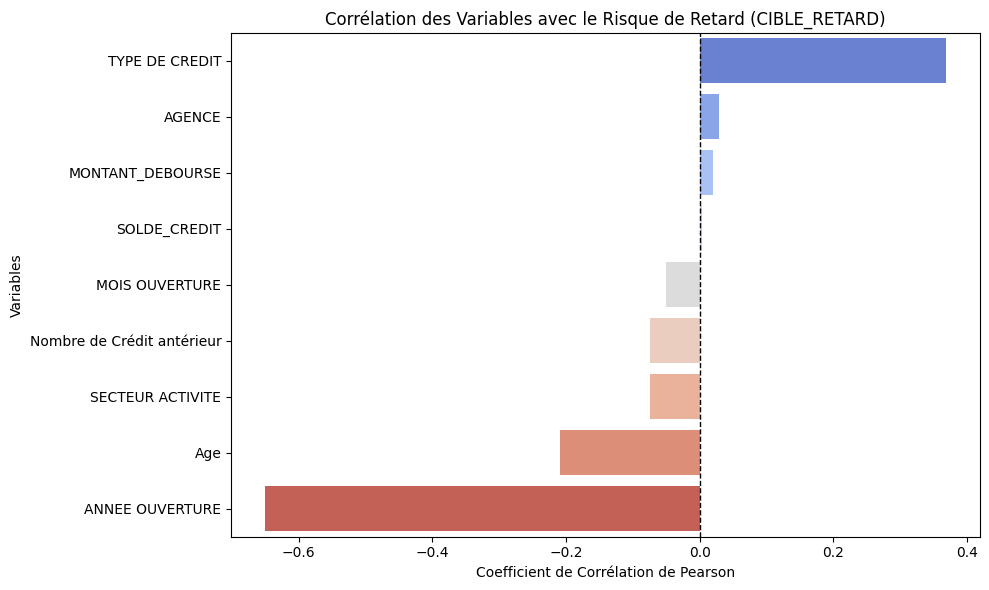

In [9]:
# Calcul des corrélations de toutes les variables avec la cible 'CIBLE_RETARD'
correlations = df_clean.corr()['CIBLE_RETARD'].drop('CIBLE_RETARD').sort_values(ascending=False)

# Affichage des valeurs de corrélation
print("Coefficients de corrélation avec CIBLE_RETARD :")
print(correlations)

# Visualisation graphique des corrélations
plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index, palette='coolwarm', hue=correlations.index, legend=False)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.title('Corrélation des Variables avec le Risque de Retard (CIBLE_RETARD)')
plt.xlabel('Coefficient de Corrélation de Pearson')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

### Étape 6 : Sauvegarde des Artefacts et Fonction de Prédiction pour le Déploiement

Pour pouvoir déployer notre modèle, nous devons exporter :
1. Le modèle XGBoost entraîné.
2. Les `LabelEncoder` utilisés pour transformer les colonnes catégorielles (`AGENCE`, `SECTEUR ACTIVITE`, `TYPE DE CREDIT`).
3. La valeur de la médiane pour remplir les éventuelles valeurs manquantes de `Nombre de Crédit antérieur`.

In [10]:
import pickle
import pandas as pd
import numpy as np

# 1. Ré-ajustement et sauvegarde des encodeurs sur le jeu complet pour le déploiement
encoders = {}
cat_cols = ['AGENCE', 'SECTEUR ACTIVITE', 'TYPE DE CREDIT']

for col in cat_cols:
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder()
    # On l'entraîne sur les données d'origine brutes (en gérant les NaN ou types)
    le.fit(df[col].astype(str))
    encoders[col] = le

# Sauvegarde du modèle XGBoost, des encodeurs et des métadonnées de prétraitement
artifacts = {
    'model': models['XGBoost'],
    'encoders': encoders,
    'median_credits': median_credits,
    'features': list(X.columns)
}

artifacts_path = 'model_credit_risk_artifacts.pkl'
with open(artifacts_path, 'wb') as f:
    pickle.dump(artifacts, f)

print(f"Tous les artefacts nécessaires ont été sauvegardés avec succès dans : {artifacts_path}")

Tous les artefacts nécessaires ont été sauvegardés avec succès dans : model_credit_risk_artifacts.pkl


Voici la fonction de prédiction packagée qui simule le comportement qu'aura l'API de déploiement en recevant de nouvelles données brutes :

In [11]:
def predire_risque_nouveau_client(input_data, path_artifacts='model_credit_risk_artifacts.pkl'):
    """
    Prend en entrée un dictionnaire contenant les caractéristiques brutes d'un client
    et retourne la prédiction du risque ainsi que la probabilité.
    """
    # Chargement des artefacts de production
    with open(path_artifacts, 'rb') as f:
        saved_stuff = pickle.load(f)

    model_prod = saved_stuff['model']
    encoders_prod = saved_stuff['encoders']
    median_credits_prod = saved_stuff['median_credits']
    required_features = saved_stuff['features']

    # Conversion de l'entrée en DataFrame d'une ligne
    df_new = pd.DataFrame([input_data])

    # 1. Prétraitement : Remplissage des valeurs manquantes
    if 'Nombre de Crédit antérieur' in df_new.columns:
        df_new['Nombre de Crédit antérieur'] = df_new['Nombre de Crédit antérieur'].fillna(median_credits_prod)
    else:
        df_new['Nombre de Crédit antérieur'] = median_credits_prod

    # 2. Prétraitement : Encodage des colonnes catégorielles
    for col in ['AGENCE', 'SECTEUR ACTIVITE', 'TYPE DE CREDIT']:
        if col in df_new.columns:
            encoder = encoders_prod[col]
            val_str = str(df_new.loc[0, col])
            # Gestion des nouvelles catégories non vues lors de l'entraînement
            if val_str in encoder.classes_:
                df_new[col] = encoder.transform([val_str])[0]
            else:
                # Si catégorie inconnue, on lui attribue une valeur par défaut ou la première classe
                df_new[col] = 0

    # Réalignement des colonnes dans le bon ordre
    df_new = df_new[required_features]

    # 3. Prédiction
    probabilite = model_prod.predict_proba(df_new)[0][1]
    prediction = int(model_prod.predict(df_new)[0])

    statut_risque = "🚨 À RISQUE DE RETARD" if prediction == 1 else "✅ SANS RISQUE MAJEUR"

    return {
        'prediction_code': prediction,
        'decision': statut_risque,
        'probabilite_risque': round(float(probabilite) * 100, 2)
    }

# --- Test de démonstration avec un profil fictif ---
nouveau_client = {
    'AGENCE': 'MECYD',
    'SECTEUR ACTIVITE': 'CONSTRUCTION',
    'TYPE DE CREDIT': 'CONSOMMATION', # Correspond au code de type de crédit utilisé
    'ANNEE OUVERTURE': 2026,
    'MOIS OUVERTURE': 6,
    'Age': 28,
    'Nombre de Crédit antérieur': np.nan, # Devrait être remplacé par la médiane (4.0)
    'SOLDE_CREDIT': 150000.0,
    'MONTANT_DEBOURSE': 500000
}

resultat = predire_risque_nouveau_client(nouveau_client)
print("Résultat de l'analyse du nouveau client :")
print(resultat)

Résultat de l'analyse du nouveau client :
{'prediction_code': 0, 'decision': '✅ SANS RISQUE MAJEUR', 'probabilite_risque': 0.01}
